# ***2. Cleaning*** — raw House 1 → clean 1-minute data

**Goal:** turn the two raw files of House 1 into **one table with one row per minute**.

Every step has the same layout: **Problem** (what we saw in notebook 1) → **Solution** → code → a quick check.

| Step | Problem | Solution |
|---|---|---|
| 1 | `Time` is text | convert to datetime |
| 2 | Part 1 and Part 2 overlap | use Part 1 until it ends, then Part 2 |
| 3 | Part 1 is not sorted | sort by time |
| 4 | Duplicate rows | drop exact copies, keep the last row at a repeated timestamp |
| 5 | Appliance spikes above 4,000 W | set them to `NaN` |
| 6 | Frozen readings (logger stopped) | find them, mark them later |
| 7 | Irregular sampling | resample to 1 minute (mean) |
| 8 | Short missing gaps | fill gaps of 5 minutes or less |
| 9 | Long outages | do **not** fill, add flag columns |

Three numbers are my own judgement: **4,000 W** (spike limit), **5 minutes** (longest gap we fill) and **30 minutes** (a flat line this long is "frozen"). I explain each one where it is used.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("dark")
pd.options.display.float_format = "{:,.2f}".format      # show 2 decimals and thousands commas

NAMES = {"Aggregate": "Aggregate", "Appliance1": "Fridge", "Appliance2": "Freezer (1)", "Appliance3": "Freezer (2)",
         "Appliance4": "Washer Dryer", "Appliance5": "Washing Machine", "Appliance6": "Dishwasher",
         "Appliance7": "Computer", "Appliance8": "Television Site", "Appliance9": "Electric Heater"}
CHANNELS = list(NAMES)         # aggregate + 9 appliances
APPLIANCES = CHANNELS[1:]      # the 9 appliances only

## Step 1: Load and parse the time

**Problem:** `Time` is stored as text.
**Solution:** convert it to a real datetime in a new column `ts`.

We also start a small dictionary `summary` where every step writes its counts. At the end it becomes a table.

In [2]:
raw1 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part1.csv")
raw2 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part2.csv")

raw1["ts"] = pd.to_datetime(raw1["Time"])
raw2["ts"] = pd.to_datetime(raw2["Time"])

summary = {}
summary["1. rows loaded (Part 1 + Part 2)"] = len(raw1) + len(raw2)
print("rows loaded:", len(raw1) + len(raw2), "| bad timestamps:", int(raw1["ts"].isna().sum() + raw2["ts"].isna().sum()))

rows loaded: 8518763 | bad timestamps: 0


## Step 2: Part 1 and Part 2 overlap

**Problem:** both files cover the same house in the same 95 days. Stacking them would count those days twice.
**Solution:** use **Part 1 until it ends**, and **Part 2 only after that**.

Why Part 1 in the overlap? In notebook 1 we saw that Part 1 shows an outage as a **gap**, while Part 2 hides it as a flat line. Gaps are easier to see and flag.

In [3]:
part1_end = raw1["ts"].max()
df = pd.concat([raw1, raw2[raw2["ts"] > part1_end]], ignore_index=True)

summary["2. Part 2 rows dropped (overlap with Part 1)"] = int((raw2["ts"] <= part1_end).sum())
print("Part 1 ends at:", part1_end)
print("rows now:", len(df))

Part 1 ends at: 2014-10-01 01:27:07
rows now: 7573360


## Step 3: Sort by time

**Problem:** Part 1 goes back in time in two places.
**Solution:** sort by `ts`. `kind="stable"` keeps the original order of rows that have the same time.

Known side effect: on 27 Oct 2013 the clock repeated the hour 01:00–02:00. After sorting, the rows of that hour from both passes are mixed. It is one hour out of two years, so I accept it and note it as a limitation.

In [4]:
df = df.sort_values("ts", kind="stable").reset_index(drop=True)
print("sorted:", df["ts"].is_monotonic_increasing)

sorted: True


## Step 4: Duplicates

**Problem:** many rows repeat a timestamp. Some are exact copies, some have different values.
**Solution:**
1. **Exact copies** → drop them.
2. **Same timestamp, different values** → **keep the last row**. The logger writes rows in order, so the last one is the newest reading.

First, does the choice (first or last) matter? I compare the 1-minute aggregate under both rules.

In [5]:
n = len(df)
df = df.drop_duplicates(subset=["ts"] + CHANNELS)               # 1) exact copies
summary["3. exact duplicate rows removed"] = n - len(df)

# does "keep first" or "keep last" change the result?
by_first = df.drop_duplicates("ts", keep="first").set_index("ts")["Aggregate"].resample("1min").mean()
by_last = df.drop_duplicates("ts", keep="last").set_index("ts")["Aggregate"].resample("1min").mean()
diff = (by_first - by_last).abs()
print(f"minutes that differ: {int((diff > 0).sum()):,} of {int(diff.notna().sum()):,} | average difference: {diff.mean():.2f} W")

minutes that differ: 29,550 of 797,809 | average difference: 0.24 W


In [6]:
n = len(df)
df = df.drop_duplicates(subset="ts", keep="last")               # 2) same timestamp: keep the last
summary["4. same-timestamp rows removed (kept the last)"] = n - len(df)

print("duplicate timestamps left:", int(df["ts"].duplicated().sum()))

duplicate timestamps left: 0


Only a small share of minutes change and the average difference is tiny, so the rule is not critical. I use **keep last** because it is simple to explain.

## Step 5: Appliance spikes

**Problem:** some appliance readings are impossible (up to 98,301 W). They look like sensor glitches.
**Solution:** set every appliance reading above **4,000 W** to `NaN`.

- 4,000 W is the same limit the official cleaning uses, and it is far above what a home appliance here really draws (the washing machine peaks at about 2.5 kW).
- We do this **before resampling**. Otherwise one 98,301 W reading would ruin the average of its whole minute.
- We do **not** touch the `Aggregate`: a whole house can really go above 4 kW (notebook 1, section 4.3).

In [7]:
spikes = df[APPLIANCES] > 4000
summary["5. appliance readings above 4,000 W set to NaN"] = int(spikes.sum().sum())

df[APPLIANCES] = df[APPLIANCES].mask(spikes)            # mask() puts NaN where spikes is True
print("readings set to NaN:", int(spikes.sum().sum()), "| largest appliance value now:", df[APPLIANCES].max().max())

readings set to NaN: 3457 | largest appliance value now: 3657.0


## Step 6: Find the frozen readings

**Problem:** sometimes the logger stops and keeps repeating its last value (notebook 1, section 6). Those minutes look like real data but are not.
**Solution:** find stretches where the **Aggregate stays at exactly the same value for 30 minutes or more**. We only *find* them now. We mark them in step 9.

- Why the Aggregate? When the logger stops, **all channels freeze together** (checked below), so one channel is enough to detect it.
- Why 30 minutes? A real house almost never shows exactly the same watt reading for half an hour (fridges, standby loads and people keep changing it).

In [8]:
def frozen_runs(df, col, min_minutes=30, min_w=10):
    # stretches where `col` keeps exactly the same value (at least min_w watts) for min_minutes or more
    s = df[["ts", col]].dropna()
    run_id = (s[col] != s[col].shift()).cumsum()              # new id each time the value changes
    g = s.groupby(run_id).agg(value=(col, "first"), start=("ts", "min"), end=("ts", "max"))
    g["minutes"] = (g["end"] - g["start"]).dt.total_seconds() / 60
    return g[(g["minutes"] >= min_minutes) & (g["value"] >= min_w)].sort_values("start").reset_index(drop=True)

frozen = frozen_runs(df, "Aggregate")
summary["6. frozen stretches found (30+ min)"] = len(frozen)
display(frozen)
print("total frozen hours:", round(frozen["minutes"].sum() / 60, 1))

,value,start,end,minutes
0,152.00,2014-10-04 15:27:39,2014-10-04 17:05:49,98.17
1,173.00,2014-10-13 09:43:42,2014-10-13 10:32:04,48.37
2,182.00,2014-11-01 14:04:05,2014-11-01 15:15:43,71.63
3,356.00,2014-12-23 18:11:11,2014-12-23 19:10:58,59.78
4,347.00,2015-01-31 21:00:52,2015-01-31 21:48:15,47.38
5,"12,505.00",2015-02-08 13:24:00,2015-02-08 16:12:32,168.53
6,283.00,2015-02-14 08:06:29,2015-02-14 09:18:33,72.07
7,265.00,2015-02-14 15:54:23,2015-02-14 17:22:59,88.60
8,167.00,2015-02-18 16:17:38,2015-02-18 21:41:00,323.37
9,377.00,2015-02-25 21:57:13,2015-02-25 23:00:55,63.70


total frozen hours: 17.4


In [9]:
# check: in the longest frozen stretch, does every channel stop changing?
longest = frozen.loc[frozen["minutes"].idxmax()]
span = df[(df["ts"] >= longest["start"]) & (df["ts"] <= longest["end"])]
print("distinct values per channel inside the longest frozen stretch:")
print(span[CHANNELS].nunique().rename(index=NAMES).to_dict())

distinct values per channel inside the longest frozen stretch:
{'Aggregate': 1, 'Fridge': 1, 'Freezer (1)': 1, 'Freezer (2)': 1, 'Washer Dryer': 1, 'Washing Machine': 1, 'Dishwasher': 1, 'Computer': 1, 'Television Site': 1, 'Electric Heater': 1}


Every channel has **1 distinct value** (or none, if the sensor had no data), so all of them are frozen together. This supports using the Aggregate as the detector.

## Step 7: Resample to 1 minute

**Problem:** readings come every 0–15 seconds, not on a regular grid.
**Solution:** put each reading in its minute and take the **mean** of the readings in that minute (power is a level, so the mean is the natural summary).

A minute with no readings becomes `NaN`.

In [10]:
clean = df.set_index("ts")[CHANNELS].resample("1min").mean()

print("rows:", len(clean), "| from", clean.index.min(), "to", clean.index.max())
print("every step is exactly 1 minute:", bool((clean.index.to_series().diff().dropna() == pd.Timedelta("1min")).all()))
summary["7. minutes in the 1-minute table"] = len(clean)

print("\n% of minutes missing, per channel:")
display(clean.isna().mean().mul(100).rename(index=NAMES).to_frame("% missing"))

rows: 920031 | from 2013-10-09 14:06:00 to 2015-07-10 11:56:00
every step is exactly 1 minute: True

% of minutes missing, per channel:


,% missing
Aggregate,13.28
Fridge,13.55
Freezer (1),13.64
Freezer (2),13.44
Washer Dryer,13.32
Washing Machine,14.19
Dishwasher,13.29
Computer,13.29
Television Site,13.46
Electric Heater,23.15


## Step 8: Fill short gaps

**Problem:** some minutes are `NaN`. A few are tiny holes, others are real outages.
**Solution:** **fill gaps of 5 minutes or less** with the last known value (forward fill). Longer gaps stay `NaN`.

Why forward fill? The logger only writes when the load *changes*, so the last value normally still holds for a short time.

Why 5 minutes? Let's look at how long the missing stretches are:

In [11]:
isna = clean["Aggregate"].isna()
run_id = (isna != isna.shift()).cumsum()
runs = isna.groupby(run_id).agg(["first", "size"])
gap_minutes = runs.loc[runs["first"], "size"]                    # length of every missing stretch, in minutes

size_group = pd.cut(gap_minutes, [0, 5, 15, 60, np.inf], labels=["1-5 min", "6-15 min", "16-60 min", "over 1 hour"])
pd.DataFrame({"number of gaps": gap_minutes.groupby(size_group, observed=False).size(),
              "total minutes": gap_minutes.groupby(size_group, observed=False).sum()})

,number of gaps,total minutes
size,,
1-5 min,489,806
6-15 min,342,3938
16-60 min,43,1239
over 1 hour,24,116239


There are many tiny blips (5 minutes or less). Then there is a group of 6–15 minute gaps, and a few long outages that hold most of the missing minutes.

At **5 minutes** the fill can never invent a washing machine cycle (a cycle lasts an hour or more). A gap of 6–15 minutes is long enough to hide the start of a cycle, so we do not fill it.

Careful: `ffill(limit=5)` alone is **not** enough. It would also fill the *first 5 minutes of a long gap* and leave the rest empty. So the function below first measures each missing stretch, and fills it only if the **whole stretch** is 5 minutes or less.

In [12]:
MAX_FILL = 5                                                      # minutes

def fill_short_gaps(s, max_len):
    # fill a NaN stretch with the last known value, but only if the WHOLE stretch is max_len minutes or less
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    stretch_len = isna.groupby(run_id).transform("sum")           # length of the NaN stretch that each NaN row belongs to
    return s.where(~(isna & (stretch_len <= max_len)), s.ffill())

was_missing = clean["Aggregate"].isna()
clean = clean.apply(fill_short_gaps, max_len=MAX_FILL)            # do it for every channel
clean["filled"] = was_missing & clean["Aggregate"].notna()        # flag: this aggregate minute was filled

summary["8. aggregate minutes filled (gaps of 5 min or less)"] = int(clean["filled"].sum())
print("aggregate minutes filled:", int(clean["filled"].sum()))
print("minutes inside gaps of 5 min or less (from the table above):", int(gap_minutes[gap_minutes <= MAX_FILL].sum()))

aggregate minutes filled: 806
minutes inside gaps of 5 min or less (from the table above): 806


## Step 9: Flag the long outages

**Problem:** long gaps and frozen stretches must not be filled or trusted.
**Solution:**
- **Frozen stretches** (from step 6): set all channels to `NaN` and set `frozen = True`.
- **Gaps** (still `NaN` after step 8, not frozen): set `gap = True`.

So each minute is in one of four states: normal, `filled`, `frozen` or `gap`.

In [13]:
clean["frozen"] = False
for start, end in zip(frozen["start"], frozen["end"]):
    clean.loc[start.floor("1min"):end, CHANNELS] = np.nan         # throw away the fake values
    clean.loc[start.floor("1min"):end, "frozen"] = True

both = int((clean["filled"] & clean["frozen"]).sum())
clean.loc[clean["frozen"], "filled"] = False                      # a frozen minute is not a "filled" minute
summary["8. aggregate minutes filled (gaps of 5 min or less)"] = int(clean["filled"].sum())
print("filled minutes that fall inside a frozen stretch (now counted as frozen):", both)
clean["gap"] = clean["Aggregate"].isna() & ~clean["frozen"]       # missing, and not because it was frozen

summary["9a. minutes flagged frozen"] = int(clean["frozen"].sum())
summary["9b. minutes flagged gap (outage, not filled)"] = int(clean["gap"].sum())

filled minutes that fall inside a frozen stretch (now counted as frozen): 42


## Check the result

In [14]:
print("sorted and one row per minute:", clean.index.is_monotonic_increasing and clean.index.is_unique)
print("largest appliance value:", clean[APPLIANCES].max().max(), "W")

state = pd.Series({
    "normal": int((~clean["filled"] & ~clean["frozen"] & ~clean["gap"]).sum()),
    "filled": int(clean["filled"].sum()),
    "frozen": int(clean["frozen"].sum()),
    "gap": int(clean["gap"].sum()),
})
print("every minute is in exactly one state:", state.sum() == len(clean))
pd.DataFrame({"minutes": state, "% of all minutes": state / state.sum() * 100})

sorted and one row per minute: True
largest appliance value: 3072.0 W
every minute is in exactly one state: True


,minutes,% of all minutes
normal,796801,86.61
filled,764,0.08
frozen,1050,0.11
gap,121416,13.20


In [15]:
pd.DataFrame({"count": pd.Series(summary)})

,count
1. rows loaded (Part 1 + Part 2),8518763
2. Part 2 rows dropped (overlap with Part 1),945403
3. exact duplicate rows removed,595935
4. same-timestamp rows removed (kept the last),49579
"5. appliance readings above 4,000 W set to NaN",3457
6. frozen stretches found (30+ min),10
7. minutes in the 1-minute table,920031
8. aggregate minutes filled (gaps of 5 min or less),764
9a. minutes flagged frozen,1050
"9b. minutes flagged gap (outage, not filled)",121416


In [16]:
os.makedirs("../data/processed", exist_ok=True)                   # data/ is not in git, so this stays local
clean.to_csv("../data/processed/house1_1min_clean.csv")
print("saved", len(clean), "rows to ../data/processed/house1_1min_clean.csv")

saved 920031 rows to ../data/processed/house1_1min_clean.csv


## Plots: before and after cleaning

Left = raw data, right = cleaned 1-minute data, for the Aggregate and two appliances (Washing Machine, Fridge). Both sides use the **same y scale**. I use `plt.plot` here because it leaves a **break** where the data is `NaN`, so removed parts stay visible.

**Example 1:** a washing machine glitch (Part 1).

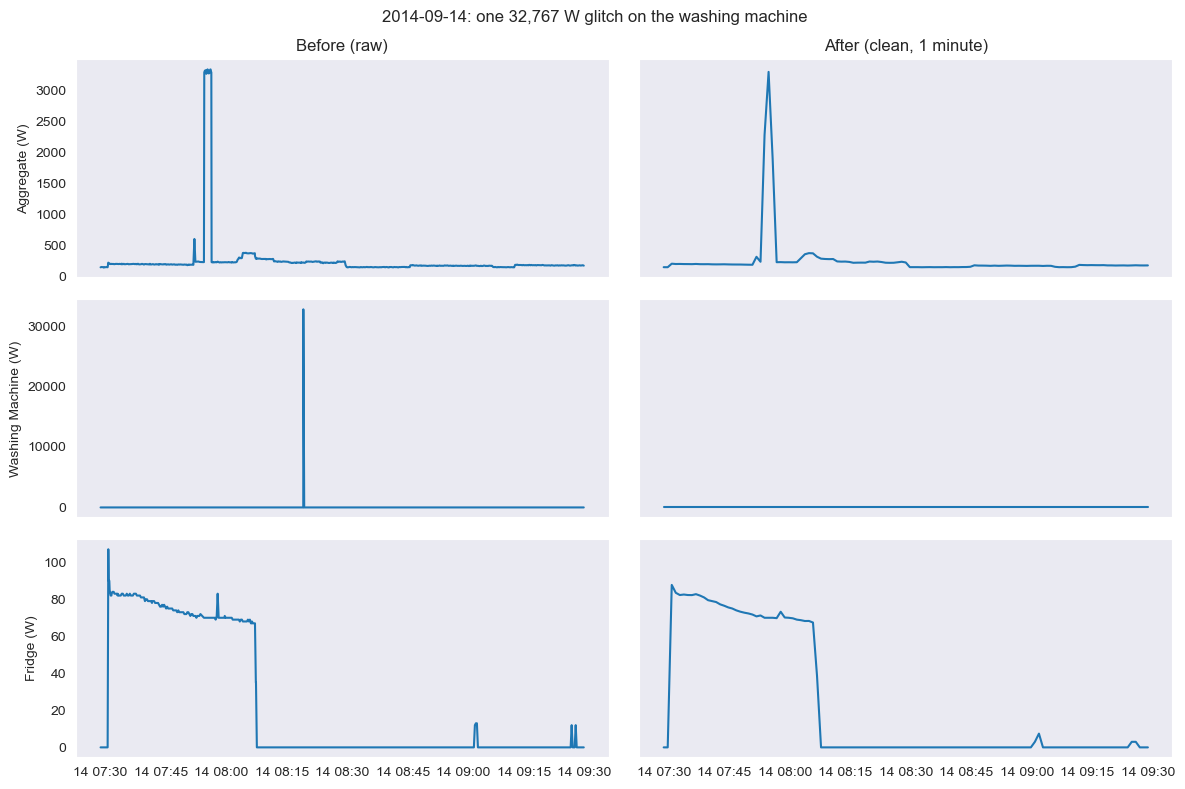

In [17]:
def before_after(start, end, raw, title):
    cols = ["Aggregate", "Appliance5", "Appliance1"]
    before = raw[(raw["ts"] >= start) & (raw["ts"] <= end)]
    after = clean.loc[start:end]

    fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, sharey="row")      # same y scale left and right
    for row, c in enumerate(cols):
        axes[row, 0].plot(before["ts"], before[c])
        axes[row, 1].plot(after.index, after[c])
        axes[row, 0].set_ylabel(NAMES[c] + " (W)")
    axes[0, 0].set_title("Before (raw)")
    axes[0, 1].set_title("After (clean, 1 minute)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

before_after("2014-09-14 07:30", "2014-09-14 09:30", raw1, "2014-09-14: one 32,767 W glitch on the washing machine")

**Before:** one washing machine reading of 32,767 W. **After:** the spike is gone (the washing machine is at 0 W, as it really was) and the aggregate and fridge keep their normal shape.

**Example 2:** a frozen stretch (Part 2).

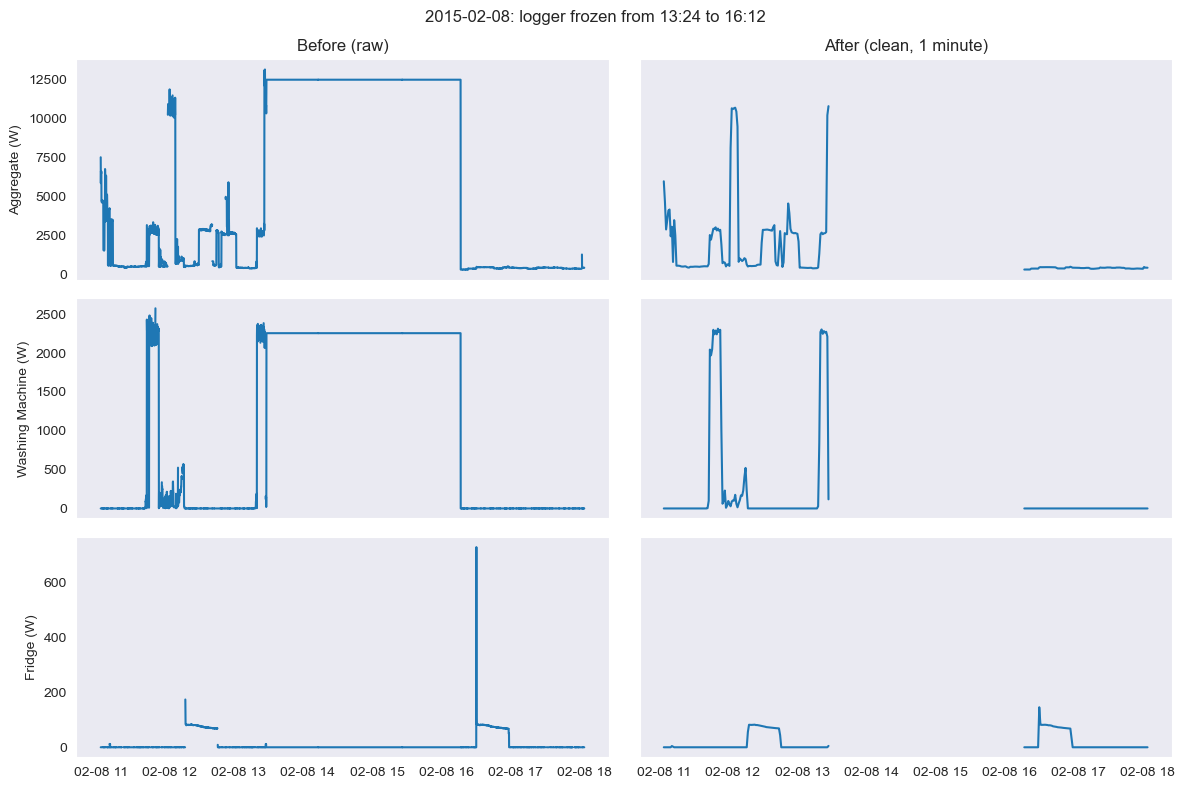

In [18]:
before_after("2015-02-08 11:00", "2015-02-08 18:00", raw2, "2015-02-08: logger frozen from 13:24 to 16:12")

**Before:** between 13:24 and 16:12 the Aggregate (12,505 W) and Washing Machine (2,256 W) are flat lines, and the fridge shows no cycle at all. **After:** those minutes are removed (a visible break), so there is no fake 3-hour washing cycle.

**Overview:** the share of minutes with aggregate data, for each day. Dips are outages.

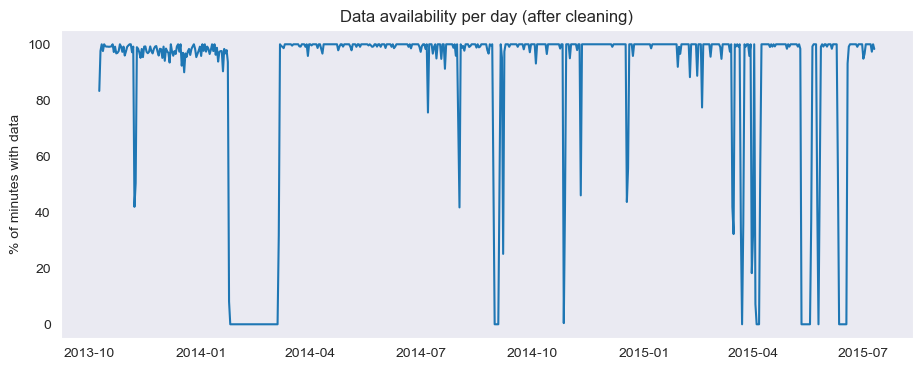

In [19]:
daily_share = clean["Aggregate"].notna().resample("1D").mean() * 100

fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(x=daily_share.index, y=daily_share.values, ax=ax)
ax.set(xlabel="", ylabel="% of minutes with data", title="Data availability per day (after cleaning)")
plt.show()

The big drop at the start of 2014 is the 41-day outage (Jan–Mar 2014). The other dips are shorter outages.

## What is still not perfect

- **Thresholds are judgement:** 4,000 W, 5 minutes and 30 minutes. A different choice would change the counts a little.
- **Frozen readings** are detected only from the Aggregate. A single appliance sensor could freeze on its own and we would not see it.
- **Part 1 uses `0` for "unavailable"**, so in Part 1 a `0` can mean "off" or "missing". We cannot tell them apart.
- **The clock:** raw time is UK local time (one repeated hour in Oct 2013, one skipped hour in Mar 2014). I did not convert it. This matters for hour-of-day plots later.
- **The aggregate is not capped.** A few extreme values (above 15 kW) are left in.